<a href="https://colab.research.google.com/github/simaltrkylmz/YZ50/blob/master/yz50_hafta12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import os
import math
import time
import numpy as np
import tiktoken
import torch
import torch.nn as nn
from torch.nn import functional as F
from dataclasses import dataclass

device = "cuda" if torch.cuda.is_available() else "cpu"
print("cihaz:", device)

# veriyi google drive'a kaydet: oturum kapansa da silinmez, tekrar token'lamaya gerek kalmaz
from google.colab import drive
drive.mount("/content/drive")
data_dir = "/content/drive/MyDrive/yz50/fineweb_edu"
os.makedirs(data_dir, exist_ok=True)

enc = tiktoken.get_encoding("gpt2")

cihaz: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Görev 1: Veriyi hazırlamak**

Veri -> FineWeb-Edu: internetten toplanıp “eğitici mi?” diye puanlanmış ve eğitici olanları tutulmuş İngilizce web sayfaları. Bunun rastgele seçilmiş 10 milyar token’lık parçasını (sample-10BT) baştan okuyup 50 milyon token’a ulaşınca durdum.

Token’lama -> metni bir kez token’a çevirip dosyalara kaydettim. Her çalıştırmada baştan token’lamaya gerek kalmıyor. Dosyalar Google Drive’da, oturum kapansa da silinmiyor.

Dosyalara bölme -> 10'ar milyon token’lık 5 dosya, her biri 20 MB (token başına 2 byte, uint16). Gerçek eğitimlerde veri belleğe sığmadığı için data loader her seferinde tek bir dosyayı yüklüyor, bitince sonrakine geçiyor.

Doğrulama -> ilk dosya val, kalan 4'ü train. Val dosyası eğitimde hiç kullanılmıyor.
<|endoftext|> -> belgelerin arasına konan ayırıcı token (50256). Model bunu görünce yeni ve ilgisiz bir belgenin başladığını öğreniyor.

In [11]:
shard_size = 10_000_000          # her dosyada 10 milyon token
num_shards = 5                   # toplam 50 milyon: 1 val + 4 train
eot = enc._special_tokens["<|endoftext|>"]    # 50256: belgeler arası ayırıcı

existing = [f for f in os.listdir(data_dir) if f.endswith(".npy")]
if len(existing) >= num_shards:
    print(f"dosyalar zaten var ({len(existing)} tane), veri hazırlama atlanıyor")
else:
    from datasets import load_dataset
    ds = load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)

    buffer = np.empty((shard_size,), dtype=np.uint16)   # bir dosyalık boş kutu
    filled = 0                                          # kutunun ne kadarı dolu
    shard_index = 0

    for doc in ds:
        tokens = np.array([eot] + enc.encode_ordinary(doc["text"]), dtype=np.uint16)
        pos = 0
        while pos < len(tokens):
            take = min(shard_size - filled, len(tokens) - pos)    # kutuya sığacak kadarını al
            buffer[filled : filled + take] = tokens[pos : pos + take]
            filled += take
            pos += take
            if filled == shard_size:                              # kutu doldu, dosyaya yaz
                split = "val" if shard_index == 0 else "train"
                path = os.path.join(data_dir, f"fineweb_{split}_{shard_index:02d}.npy")
                np.save(path, buffer)
                print(f"{path} kaydedildi")
                shard_index += 1
                filled = 0
                if shard_index == num_shards:
                    break
        if shard_index == num_shards:
            break

dosyalar zaten var (5 tane), veri hazırlama atlanıyor


## Model (hafta 11'den: weight tying, başlangıç değerleri, flash attention)

In [12]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50304      # 50257 yerine gpu dostu sayı
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768


class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)   # q, k, v birlikte
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)       # head'leri harmanla
        self.c_proj.NANOGPT_SCALE_INIT = 1                          # residual'a ekliyor, ölçeklenecek
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size()
        hs = C // self.n_head
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)   # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)


class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1                          # residual'a ekliyor, ölçeklenecek

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))


class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight   # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, "NANOGPT_SCALE_INIT"):
                std *= (2 * self.config.n_layer) ** -0.5     # residual'a ekleyenler: 0.02 / √24
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

## Data loader

In [13]:
class DataLoaderLite:
    #token dosyalarını sırayla okuyup B x T'lik batch'ler veriyor

    def __init__(self, B, T, split, data_dir=data_dir):
        self.B, self.T = B, T
        files = sorted(f for f in os.listdir(data_dir) if split in f)   # "train" ya da "val" dosyaları
        self.shards = [os.path.join(data_dir, f) for f in files]
        assert len(self.shards) > 0, f"{split} için dosya bulunamadı"
        print(f"{split}: {len(self.shards)} dosya")
        self.reset()

    def load_tokens(self, path):
        return torch.tensor(np.load(path).astype(np.int64))   # uint16 -> pytorch'un istediği int64

    def reset(self):
        #ilk dosyanın başına dön
        self.current_shard = 0
        self.tokens = self.load_tokens(self.shards[0])
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position + B * T + 1]
        x = buf[:-1].view(B, T)
        y = buf[1:].view(B, T)
        self.current_position += B * T
        if self.current_position + B * T + 1 > len(self.tokens):          # bu dosya bitti
            self.current_shard = (self.current_shard + 1) % len(self.shards)
            self.tokens = self.load_tokens(self.shards[self.current_shard])  # sonrakini yükle
            self.current_position = 0
        return x, y

## Kontrol

In [14]:
for f in sorted(os.listdir(data_dir)):
    print(f, f"{os.path.getsize(os.path.join(data_dir, f)) / 1e6:.0f} MB")

train_loader = DataLoaderLite(B=4, T=512, split="train")
val_loader = DataLoaderLite(B=4, T=512, split="val")

x, y = val_loader.next_batch()
print()
print(enc.decode(x[0, :100].tolist()))     # val dosyasının başındaki metin

fineweb_train_01.npy 20 MB
fineweb_train_02.npy 20 MB
fineweb_train_03.npy 20 MB
fineweb_train_04.npy 20 MB
fineweb_val_00.npy 20 MB
train: 4 dosya
val: 1 dosya

<|endoftext|>The Independent Jane
For all the love, romance and scandal in Jane Austen’s books, what they are really about is freedom and independence. Independence of thought and the freedom to choose.
Elizabeth’s refusal of Mr. Collins offer of marriage showed an independence seldom seen in heroines of the day. Her refusal of Mr. Darcy while triggered by anger showed a level of independence that left him shocked and stunned.
The freedom she exhibited in finally accepting him in direct


**Görev 2: Doğrulama loss’u ve örnekler**

Val loss -> train loss modelin gördüğü metindeki başarısı, val loss hiç görmediği metindeki başarısı. İkisi birlikte düşüyorsa model öğreniyor, train düşerken val duruyorsa ezberliyor. Her ölçümde val dosyasının aynı 20 batch’i kullanılıyor ki ölçümler karşılaştırılabilir olsun.

Örnek metinler -> her değerlendirmede “Hello, I’m a language model,” cümlesinden iki devam ürettiriyorum. Rastgelelik sabit seed’le yapılıyor, böylece örnekler arasındaki fark sadece modelden geliyor.

60 adımlık deneme -> val loss 10,94'ten 7,24'e indi. 0. adımda örnekler rastgele kelime parçaları, 20. adımda en sık kelimeler (the, of, a, nokta, virgül), 40-59. adımlarda “the most”, “which was” gibi kısa kalıplar. Train (7,31) ve val (7,24) çok yakın; model train verisinin sadece %5'ini gördüğü için ezberleme yok.

In [15]:
max_lr = 6e-4
min_lr = max_lr * 0.1

def get_lr(it, warmup_steps, max_steps):
    #warmup + cosine öğrenme hızı planı
    if it < warmup_steps:
        return max_lr * (it + 1) / warmup_steps
    if it > max_steps:
        return min_lr
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return min_lr + coeff * (max_lr - min_lr)


def configure_optimizers(model, weight_decay, learning_rate):
    #weight decay sadece 2 boyutlu parametrelere
    params = [p for p in model.parameters() if p.requires_grad]
    decay_params = [p for p in params if p.dim() >= 2]
    nodecay_params = [p for p in params if p.dim() < 2]
    optim_groups = [
        {"params": decay_params, "weight_decay": weight_decay},
        {"params": nodecay_params, "weight_decay": 0.0},
    ]
    return torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8)

In [16]:
val_loader = DataLoaderLite(B=4, T=512, split="val")

@torch.no_grad()
def evaluate_val(model, val_steps=20):
    #val dosyasının başındaki 20 batch'in ortalama loss'u
    model.eval()
    val_loader.reset()                 # her seferinde aynı 20 batch
    total = 0.0
    for _ in range(val_steps):
        x, y = val_loader.next_batch()
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            _, loss = model(x, y)
        total += loss.item()
    model.train()
    return total / val_steps

val: 1 dosya


In [17]:
@torch.no_grad()
def generate_samples(model, prompt="Hello, I'm a language model,", num_samples=2, max_new_tokens=32, top_k=50):
    #top-k ile kısa metinler üretiyor
    model.eval()
    tokens = torch.tensor(enc.encode(prompt), dtype=torch.long, device=device)
    idx = tokens.unsqueeze(0).repeat(num_samples, 1)
    g = torch.Generator(device=device).manual_seed(42)     # sabit rastgelelik
    for _ in range(max_new_tokens):
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits, _ = model(idx[:, -model.config.block_size:])
        logits = logits[:, -1, :50257].float()             # 47 hayalî token'ı dışarıda bırak
        probs = F.softmax(logits, dim=-1)
        topk_probs, topk_ids = torch.topk(probs, top_k, dim=-1)
        choice = torch.multinomial(topk_probs, 1, generator=g)
        idx = torch.cat((idx, torch.gather(topk_ids, -1, choice)), dim=1)
    model.train()
    return [enc.decode(idx[i].tolist()) for i in range(num_samples)]

In [29]:
def train_run(max_steps, warmup_steps, eval_interval, total_batch_size=32768, B=4, T=512, save_path=None):
    grad_accum_steps = total_batch_size // (B * T)
    torch.manual_seed(1337)
    raw_model = GPT(GPTConfig()).to(device)
    model = torch.compile(raw_model)          # eğitim için hızlı hâli
    optimizer = configure_optimizers(raw_model, weight_decay=0.1, learning_rate=max_lr)
    scaler = torch.amp.GradScaler("cuda")
    train_loader = DataLoaderLite(B=B, T=T, split="train")
    history = {"step": [], "train": [], "val_step": [], "val": []}
    print(f"büyük batch: {total_batch_size:,} token | biriktirme: {grad_accum_steps} | adım: {max_steps}\n")

    t_start = time.time()
    for step in range(max_steps):
        # --- değerlendirme ---
        if step % eval_interval == 0 or step == max_steps - 1:
            val_loss = evaluate_val(model)
            history["val_step"].append(step)
            history["val"].append(val_loss)
            samples = generate_samples(raw_model, num_samples=2)
            print(f"\n---------- DEĞERLENDİRME | adım {step} | {(time.time() - t_start) / 60:.1f} dk ----------")
            print(f"val loss : {val_loss:.4f}")
            for i, s in enumerate(samples, start=1):
                print(f"örnek {i}  : {s.replace(chr(10), ' ')}")
            print("-" * 60)
            if save_path and step > 0:
                torch.save(raw_model.state_dict(), save_path)

        # --- eğitim adımı (hafta 11 ile aynı) ---
        t0 = time.time()
        optimizer.zero_grad()
        loss_accum = 0.0
        for micro_step in range(grad_accum_steps):
            x, y = train_loader.next_batch()
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits, loss = model(x, y)
            loss = loss / grad_accum_steps
            loss_accum += loss.detach()
            scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        lr = get_lr(step, warmup_steps, max_steps)
        for param_group in optimizer.param_groups:
            param_group["lr"] = lr
        scaler.step(optimizer)
        scaler.update()
        torch.cuda.synchronize()
        dt = time.time() - t0

        history["step"].append(step)
        history["train"].append(loss_accum.item())
        if step % 10 == 0:
            print(f"eğitim | adım {step:4d} | train loss: {loss_accum.item():.4f} | lr: {lr:.2e} "
                  f"| norm: {norm:.2f} | {total_batch_size / dt:,.0f} token/s")

    total_time = time.time() - t_start
    print(f"\ntoplam süre: {total_time / 60:.1f} dk | görülen token: {max_steps * total_batch_size:,} "
          f"| ortalama: {max_steps * total_batch_size / total_time:,.0f} token/s")
    print(f"son train loss: {history['train'][-1]:.4f} | son val loss: {history['val'][-1]:.4f}")

    if save_path:
        torch.save(raw_model.state_dict(), save_path)
        print(f"model kaydedildi: {save_path}")
    return raw_model, history

In [33]:
model, history = train_run(max_steps=60, warmup_steps=10, eval_interval=20)

train: 4 dosya
büyük batch: 32,768 token | biriktirme: 16 | adım: 60


---------- DEĞERLENDİRME | adım 0 | 0.0 dk ----------
val loss : 10.9444
örnek 1  : Hello, I'm a language model,ulaula flaw Creatinganticallyrices� attachment sore BITolls clothing relentlesspped refin refin flaw EffectiveTesla mercyWritwasherwasher relentlessEPA shipmentithmetic,Tesla Chandra Christina discrete
örnek 2  : Hello, I'm a language model,iggs murderers continuass745 Realms warp senateOULD Effective Voc mysteriously684Listenerws lesbianimated counter politician obst antib AwokenDial histor rubbing hurricaneblockingWrit contributors contributors intraudd
------------------------------------------------------------
eğitim | adım    0 | train loss: 10.9484 | lr: 6.00e-05 | norm: 15.85 | 16,584 token/s
eğitim | adım   10 | train loss: 8.0960 | lr: 6.00e-04 | norm: 1.09 | 15,788 token/s

---------- DEĞERLENDİRME | adım 20 | 0.7 dk ----------
val loss : 7.6684
örnek 1  : Hello, I'm a language model, they. in w

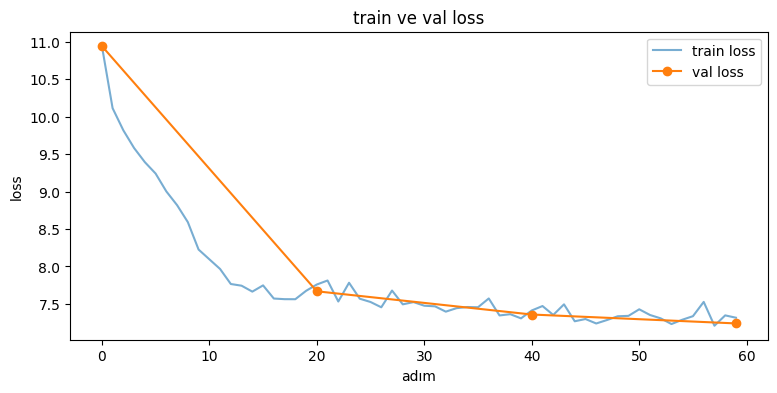

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(history["step"], history["train"], label="train loss", alpha=0.6)
plt.plot(history["val_step"], history["val"], "o-", label="val loss")
plt.xlabel("adım")
plt.ylabel("loss")
plt.title("train ve val loss")
plt.legend()
plt.show()

**Görev 3: Modeli eğitmek**

Ayarlar -> 1800 adım, her adımda 32.768 token (16 küçük batch’le gradient accumulation), 100 adım warmup, her 200 adımda bir val loss ve örnek metin. Model her değerlendirmede Drive’a kaydedildi.

Sonuçlar -> 61,5 dakika, 58.982.400 token, ortalama saniyede 15.975 token. Son train loss 4,88, son val loss 4,82.

Val loss -> 10,94'ten 4,82'ye hiç durmadan düştü ve train loss’la hep yan yana kaldı. Model 1220. adımdan sonra train verisini ikinci kez görmeye başladı ama val düşmeye devam ettiği için ezberleme yok.

Örnek metinler -> 0. adımda rastgele token’lar, 200. adımda dilbilgisi parçaları, 400. adımda cümle yapısı, 800. adımda <|endoftext|> ile belge bitirip yenisine başlamayı öğrenmiş, sonlara doğru alıntılı ve akıcı cümleler. Dilbilgisi büyük ölçüde doğru ama anlam birkaç kelime sonra kayboluyor.

Not -> 610. adımda hız düştü, çünkü data loader bir sonraki dosyayı Drive’dan yükledi.

In [35]:
save_path = "/content/drive/MyDrive/yz50/gpt2_fineweb.pt"
model, history = train_run(max_steps=1800, warmup_steps=100, eval_interval=200, save_path=save_path)

train: 4 dosya
büyük batch: 32,768 token | biriktirme: 16 | adım: 1800


---------- DEĞERLENDİRME | adım 0 | 0.0 dk ----------
val loss : 10.9444
örnek 1  : Hello, I'm a language model,ulaula flaw Creatinganticallyrices� attachment sore BITolls clothing relentlesspped refin refin flaw EffectiveTesla mercyWritwasherwasher relentlessEPA shipmentithmetic,Tesla Chandra Christina discrete
örnek 2  : Hello, I'm a language model,iggs murderers continuass745 Realms warp senateOULD Effective Voc mysteriously684Listenerws lesbianimated counter politician obst antib AwokenDial histor rubbing hurricaneblockingWrit contributors contributors intraudd
------------------------------------------------------------
eğitim | adım    0 | train loss: 10.9484 | lr: 6.00e-06 | norm: 15.85 | 16,456 token/s
eğitim | adım   10 | train loss: 9.5355 | lr: 6.60e-05 | norm: 2.32 | 15,391 token/s
eğitim | adım   20 | train loss: 8.7503 | lr: 1.26e-04 | norm: 2.58 | 15,970 token/s
eğitim | adım   30 | train loss: 7.85

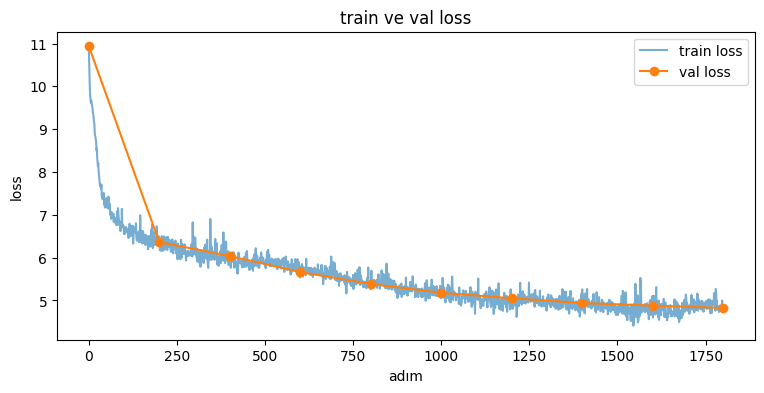

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(history["step"], history["train"], label="train loss", alpha=0.6)
plt.plot(history["val_step"], history["val"], "o-", label="val loss")
plt.xlabel("adım")
plt.ylabel("loss")
plt.title("train ve val loss")
plt.legend()
plt.show()

**Görev 4: HellaSwag**

HellaSwag -> her soruda yarım kalmış bir durum ve 4 olası devam var, sadece biri mantıklı. İnsanlar %95'ten fazlasını buluyor, rastgele tahmin %25. Yanlış şıklar dil modellerini kandırmak için seçilmiş: dilbilgisi düzgün ama anlamsız.

Nasıl ölçtüm -> bağlamın arkasına her şıkkı ekleyip modele verdim, şık token’larının ortalama loss’unu hesapladım. Loss’u en düşük şık, modelin en doğal bulduğu devam, yani cevabı. Şıkların uzunlukları farklı olduğu için toplam değil ortalama loss kullandım.


Sonuçlar -> benim modelim %23,83, OpenAI’ın GPT-2'si %29,58 (Karpathy’nin videosundaki %29,55 ile aynı). Benim modelim rastgele tahmin seviyesinde.

Fark nereden geliyor -> mimari aynı, parametre sayısı aynı, fark tamamen eğitimden. Benim modelim 1 saatte 59 milyon token gördü, OpenAI’ınki çok daha fazla GPU’da milyarlarca token gördü. Model önce dilbilgisini, çok sonra dünya bilgisini öğreniyor; HellaSwag dünya bilgisini ölçtüğü için dilbilgisi aşamasındaki benim modelim rastgeleden farklı bir şey yapamıyor. Rastgelenin biraz altında kalması, yanlış şıkların zayıf modelleri kandıracak şekilde seçilmiş olmasından. Veri türü asıl sebep değil: Karpathy aynı FineWeb-Edu verisiyle 10 milyar token eğitince OpenAI’ın modelini geçiyor.

In [39]:
import urllib.request
import pandas as pd

hs_path = "/content/drive/MyDrive/yz50/hellaswag_val.parquet"
if not os.path.exists(hs_path):
    url = "https://huggingface.co/datasets/Rowan/hellaswag/resolve/refs%2Fconvert%2Fparquet/default/validation/0000.parquet"
    urllib.request.urlretrieve(url, hs_path)

df = pd.read_parquet(hs_path)
hellaswag = [{"ctx": r["ctx"], "endings": list(r["endings"]), "label": int(r["label"])}
             for _, r in df.iterrows()]
print(f"{len(hellaswag):,} soru")

ex = hellaswag[0]
print("\nbağlam:", ex["ctx"])
for i, e in enumerate(ex["endings"]):
    print(f"  {i}{' (doğru)' if i == ex['label'] else ''}: {e}")

10,042 soru

bağlam: A man is sitting on a roof. he
  0: is using wrap to wrap a pair of skis.
  1: is ripping level tiles off.
  2: is holding a rubik's cube.
  3 (doğru): starts pulling up roofing on a roof.


In [41]:
def render_example(example):
    #bir soruyu 4 satırlık token tensörüne çeviriyor: her satır bağlam + bir şık
    ctx_tokens = enc.encode(example["ctx"])
    rows, masks = [], []
    for end in example["endings"]:
        end_tokens = enc.encode(" " + end)
        rows.append(ctx_tokens + end_tokens)
        masks.append([0] * len(ctx_tokens) + [1] * len(end_tokens))   # 1: şıkkın token'ları

    max_len = max(len(r) for r in rows)
    tokens = torch.zeros((4, max_len), dtype=torch.long)
    mask = torch.zeros((4, max_len), dtype=torch.long)
    for i, (r, m) in enumerate(zip(rows, masks)):
        tokens[i, :len(r)] = torch.tensor(r)
        mask[i, :len(m)] = torch.tensor(m)
    return tokens, mask, example["label"]

In [42]:
def most_likely_ending(logits, tokens, mask):
    #her satırda şıkkın token'larının ortalama loss'unu hesaplıyor, en düşüğü seçiyor
    shift_logits = logits[:, :-1, :]       # t. konumdaki tahmin...
    shift_tokens = tokens[:, 1:]           # ...t+1. konumdaki gerçek token'ı tahmin ediyor
    shift_mask = mask[:, 1:]
    losses = F.cross_entropy(
        shift_logits.reshape(-1, shift_logits.size(-1)).float(),
        shift_tokens.reshape(-1),
        reduction="none",                   # her token'ın loss'unu ayrı ayrı ver
    ).view(tokens.size(0), -1)
    avg_loss = (losses * shift_mask).sum(dim=1) / shift_mask.sum(dim=1)   # sadece şık token'ları
    return avg_loss.argmin().item()

In [43]:
@torch.no_grad()
def evaluate_hellaswag(get_logits, n=None):
    #get_logits: token'ları alıp logits döndüren fonksiyon. n: kaç soru (None = hepsi)
    examples = hellaswag if n is None else hellaswag[:n]
    correct = 0
    for i, ex in enumerate(examples):
        tokens, mask, label = render_example(ex)
        tokens, mask = tokens.to(device), mask.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = get_logits(tokens)
        pred = most_likely_ending(logits, tokens, mask)
        correct += int(pred == label)
        if (i + 1) % 2000 == 0:
            print(f"{i+1:,} soru | şu ana kadarki doğruluk: %{correct / (i + 1) * 100:.2f}")
    acc = correct / len(examples)
    print(f"sonuç: {correct:,} / {len(examples):,} doğru | doğruluk: %{acc * 100:.2f}")
    return acc

In [44]:
model.eval()
acc_mine = evaluate_hellaswag(lambda t: model(t)[0])

2,000 soru | şu ana kadarki doğruluk: %26.15
4,000 soru | şu ana kadarki doğruluk: %26.02
6,000 soru | şu ana kadarki doğruluk: %25.25
8,000 soru | şu ana kadarki doğruluk: %24.62
10,000 soru | şu ana kadarki doğruluk: %23.87
sonuç: 2,393 / 10,042 doğru | doğruluk: %23.83


In [45]:
from transformers import GPT2LMHeadModel

model_hf = GPT2LMHeadModel.from_pretrained("gpt2").to(device).eval()
acc_hf = evaluate_hellaswag(lambda t: model_hf(t).logits)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

2,000 soru | şu ana kadarki doğruluk: %33.60
4,000 soru | şu ana kadarki doğruluk: %32.85
6,000 soru | şu ana kadarki doğruluk: %31.33
8,000 soru | şu ana kadarki doğruluk: %30.18
10,000 soru | şu ana kadarki doğruluk: %29.59
sonuç: 2,970 / 10,042 doğru | doğruluk: %29.58
